In [ ]:

!pip -q install ucimlrepo


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Load the official UCI dataset
dataset = fetch_ucirepo(id=468)

X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

# Combine features and target
df = pd.concat([X_raw, y_raw], axis=1)

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nFirst 5 rows:")
display(df.head())


Number of rows: 12330
Number of columns: 18

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0



First 5 rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:

print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

# Percentage of missing values
missing_percent = (df.isnull().mean() * 100).round(2)

print("\nMissing-value percentage:")
display(missing_percent.to_frame("Missing Percentage"))

# We will handle missing values through preprocessing if required.


Missing values in each column:


,Missing Values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Total missing values: 0
Duplicate rows: 125

Missing-value percentage:


,Missing Percentage
Administrative,0.0
Administrative_Duration,0.0
Informational,0.0
Informational_Duration,0.0
ProductRelated,0.0
ProductRelated_Duration,0.0
BounceRates,0.0
ExitRates,0.0
PageValues,0.0
SpecialDay,0.0


Target variable: Revenue

Class counts:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Class percentages:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


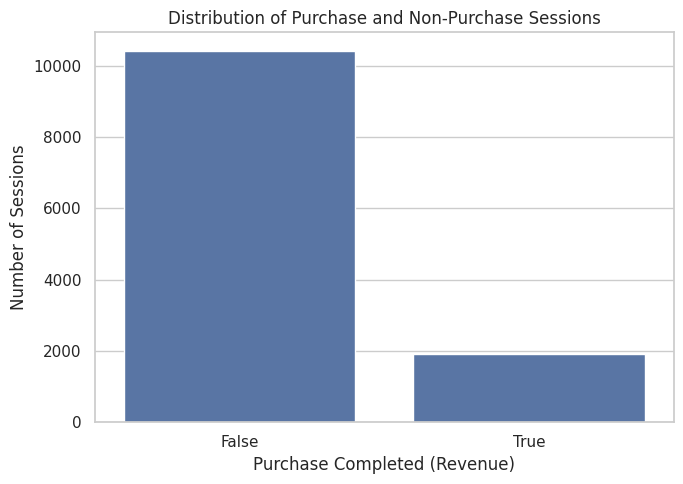

In [ ]:

target = "Revenue"

print("Target variable:", target)
print("\nClass counts:")
print(df[target].value_counts())

print("\nClass percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target)
plt.title("Distribution of Purchase and Non-Purchase Sessions")
plt.xlabel("Purchase Completed (Revenue)")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()


In [ ]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Potential outliers using the IQR method:\n")

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": count
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)


Potential outliers using the IQR method:



,Feature,Lower Bound,Upper Bound,Potential Outliers
0,Administrative,-6.000000,10.000000,404
1,Administrative_Duration,-139.884375,233.140625,1172
2,Informational,0.000000,0.000000,2631
3,Informational_Duration,0.000000,0.000000,2405
4,ProductRelated,-39.500000,84.500000,987
5,ProductRelated_Duration,-1735.892070,3384.186784,961
6,BounceRates,-0.025219,0.042031,1551
7,ExitRates,-0.039286,0.103571,1099
8,PageValues,0.000000,0.000000,2730
9,SpecialDay,0.000000,0.000000,1251


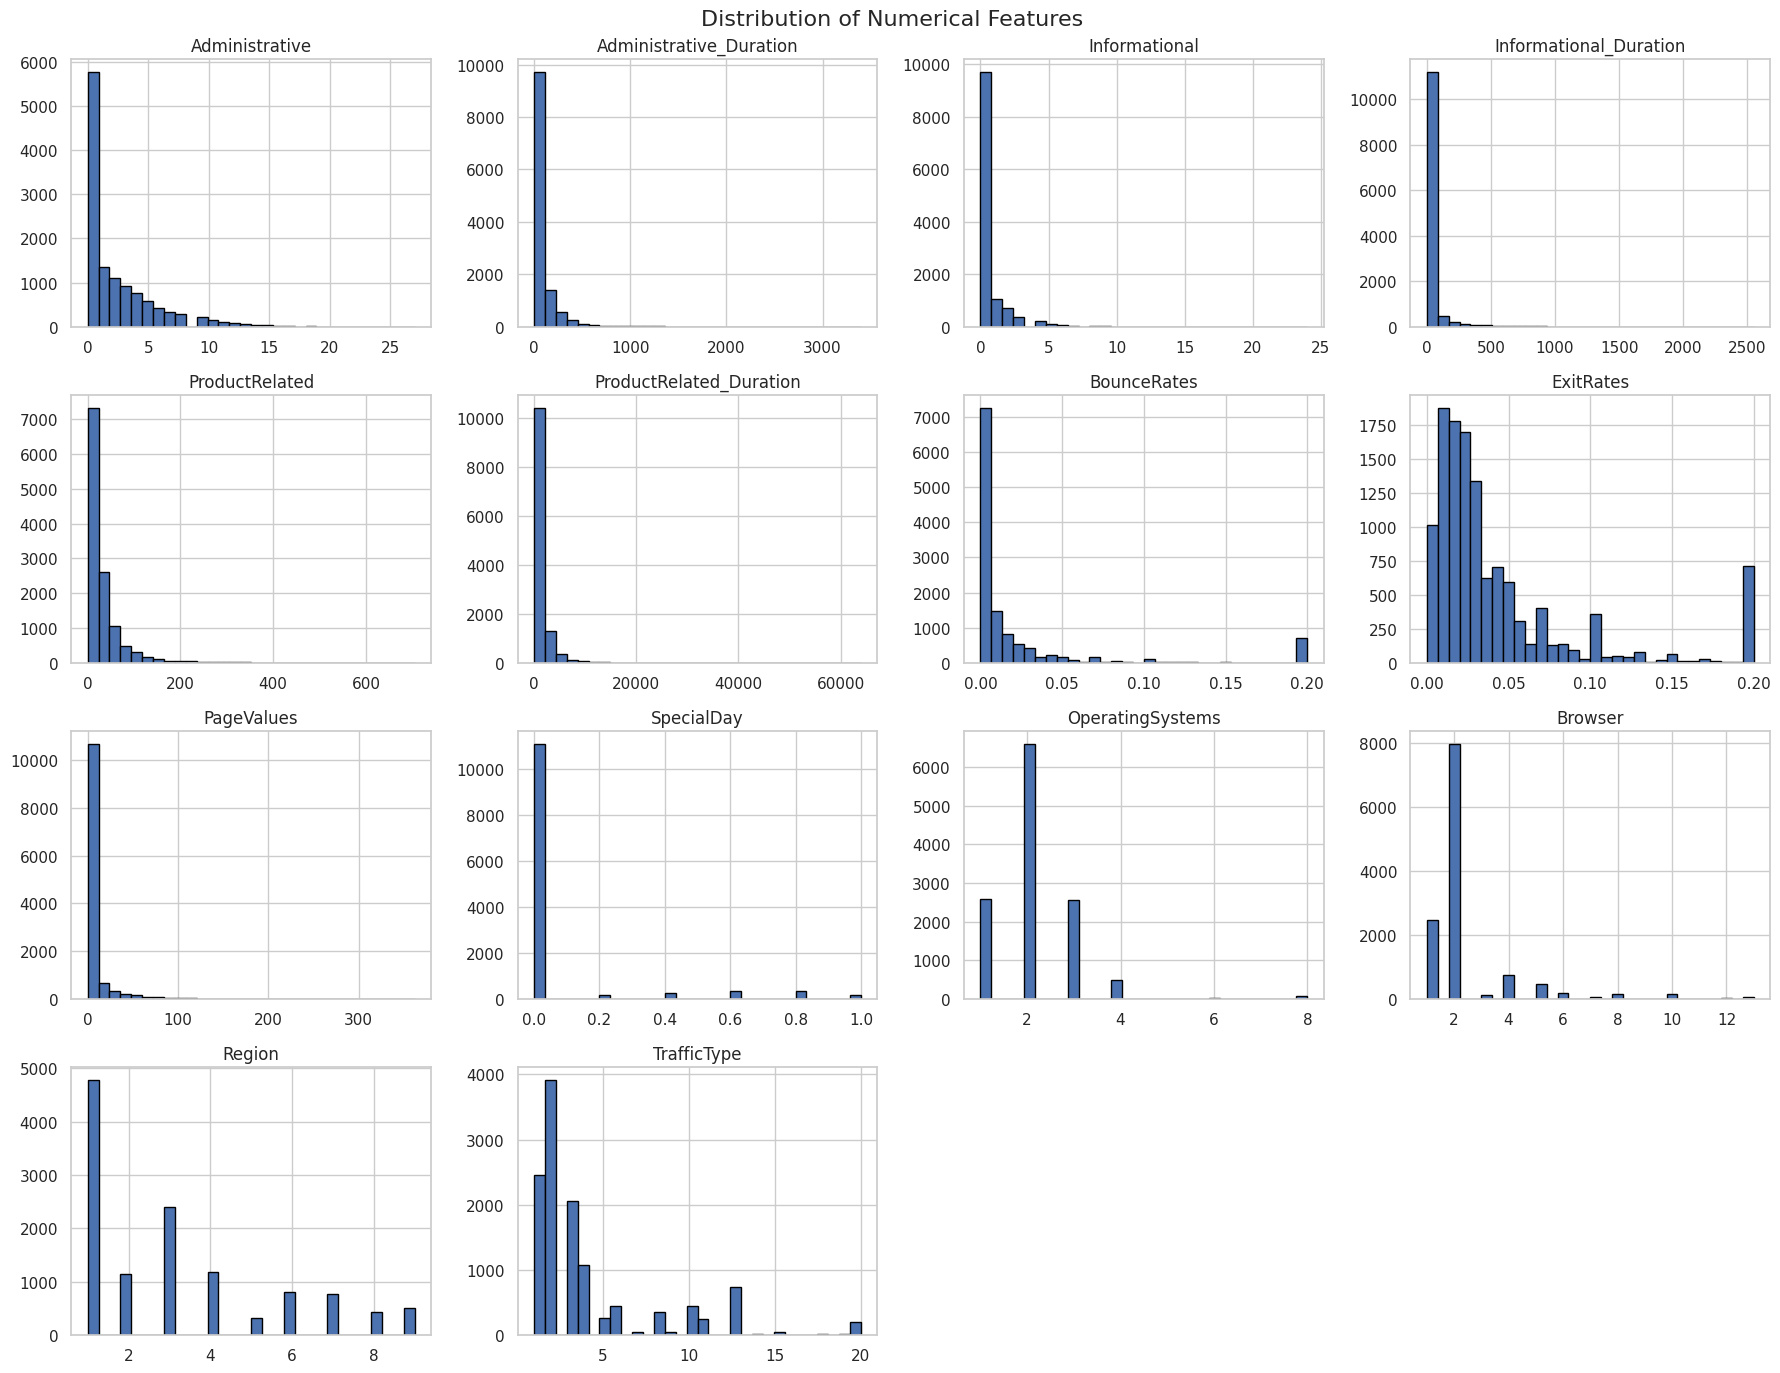

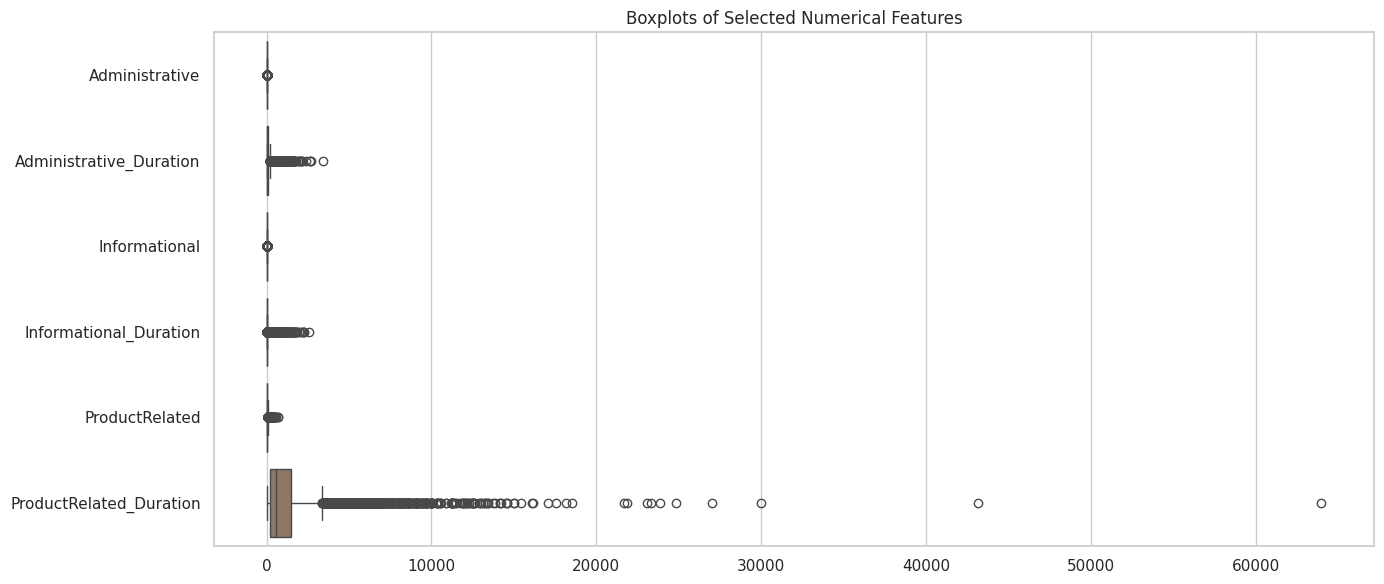

In [ ]:

# Histograms for numerical features
df[numeric_cols].hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

# Boxplots for selected numerical features
selected_cols = numeric_cols[:6]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[selected_cols], orient="h")
plt.title("Boxplots of Selected Numerical Features")
plt.tight_layout()
plt.show()


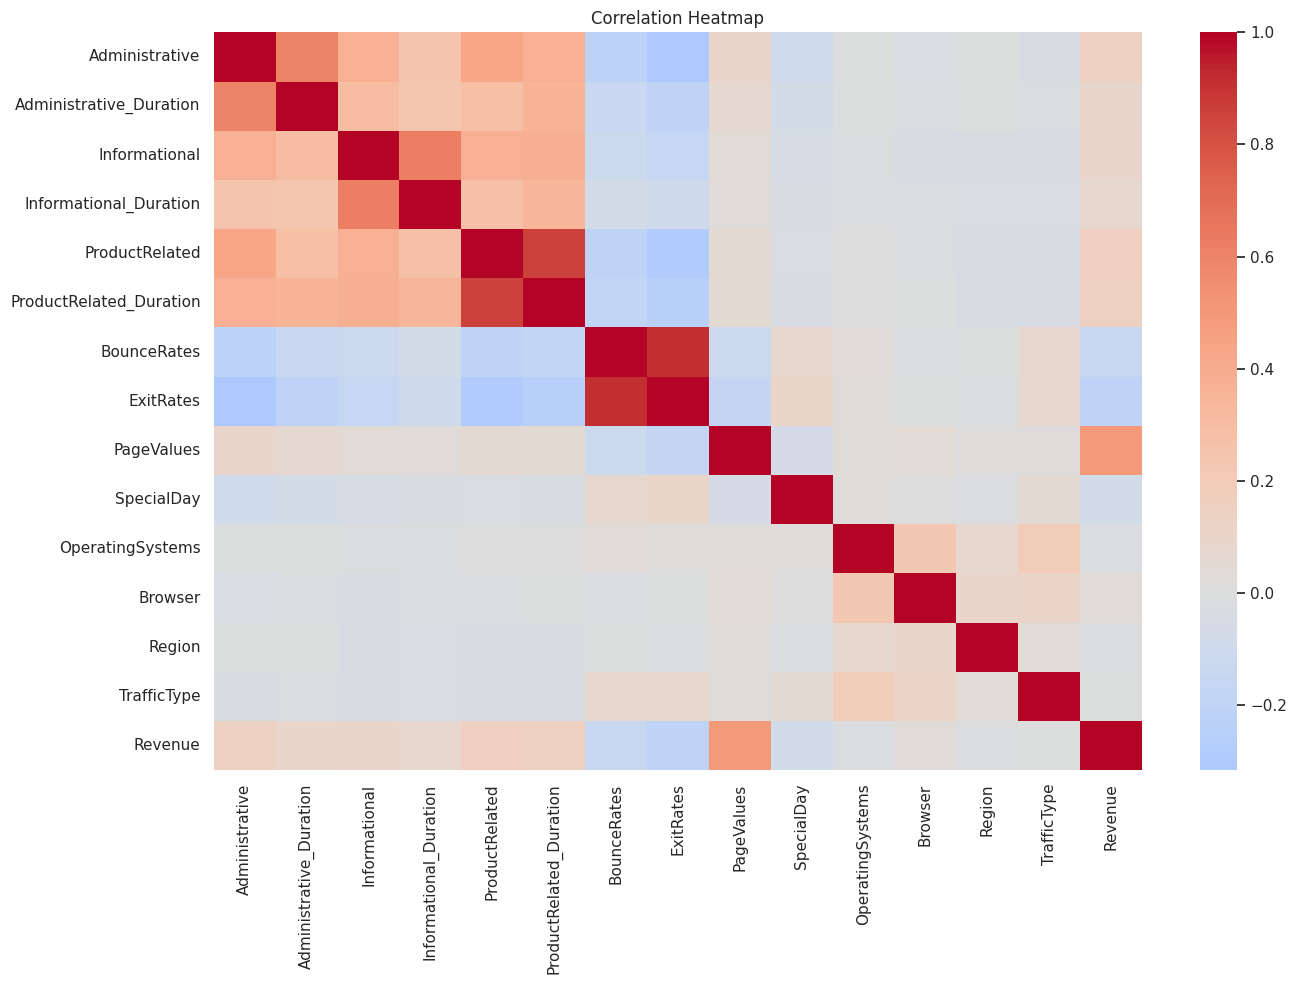

Features most correlated with Revenue:


,Correlation with Revenue
PageValues,0.492569
ExitRates,-0.207071
ProductRelated,0.158538
ProductRelated_Duration,0.152373
BounceRates,-0.150673
Administrative,0.138917
Informational,0.095200
Administrative_Duration,0.093587
SpecialDay,-0.082305
Informational_Duration,0.070345


In [ ]:

# Convert the Boolean target to numeric for correlation analysis
corr_df = df[numeric_cols].copy()
corr_df[target] = df[target].astype(int)

correlation_matrix = corr_df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Features most correlated with Revenue:")
display(
    correlation_matrix["Revenue"]
    .drop("Revenue")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation with Revenue")
)


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Separate input features and target
X = df.drop(columns=["Revenue"]).copy()
y = df["Revenue"].astype(bool).astype(int)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split data: 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training percentage:", round(len(X_train) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

# Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical features: ['Month', 'VisitorType', 'Weekend']

Training samples: 8631
Testing samples: 3699
Training percentage: 70.0
Testing percentage: 30.0


In [ ]:

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

baseline_results = []
baseline_pipelines = {}

for name, model in baseline_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    baseline_pipelines[name] = pipe

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

baseline_table = pd.DataFrame(baseline_results)
display(
    baseline_table.sort_values("F1 Score", ascending=False)
    .round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8540,0.5194,0.7483,0.6132
1,Decision Tree,0.8581,0.5428,0.5210,0.5317
2,KNN,0.8732,0.6484,0.3934,0.4897


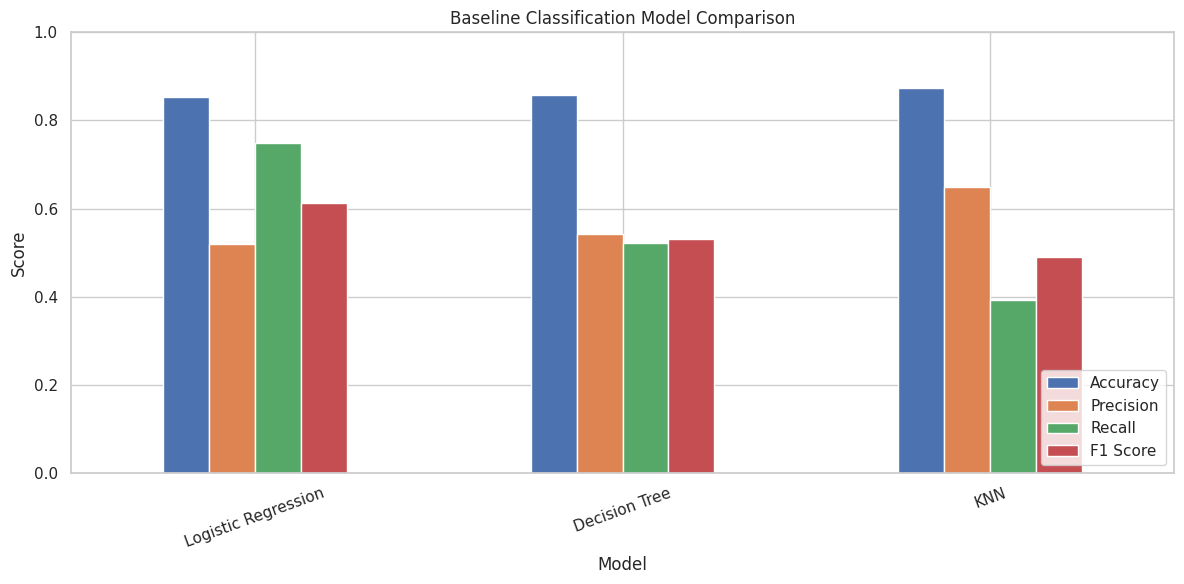

Best baseline model by F1 Score: Logistic Regression
Interpretation: Compare F1 Score and Recall, particularly because purchase sessions are less common than non-purchase sessions.


In [ ]:

baseline_plot = baseline_table.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

baseline_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Baseline Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_baseline_name = (
    baseline_table.sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

print("Best baseline model by F1 Score:", best_baseline_name)
print(
    "Interpretation: Compare F1 Score and Recall, particularly because "
    "purchase sessions are less common than non-purchase sessions."
)


In [ ]:

advanced_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

advanced_results = []
advanced_pipelines = {}

for name, model in advanced_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    advanced_pipelines[name] = pipe

    advanced_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

advanced_table = pd.DataFrame(advanced_results)
display(
    advanced_table.sort_values("F1 Score", ascending=False)
    .round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score
1,Gradient Boosting,0.8978,0.7055,0.5822,0.6379
0,Random Forest,0.8978,0.7449,0.5157,0.6095


In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_split": [2, 5]
}

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1 Score:")
print(round(grid_search.best_score_, 4))

tuned_rf = grid_search.best_estimator_


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'model__max_depth': 15, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best cross-validation F1 Score:
0.6871


In [ ]:

from sklearn.model_selection import cross_val_score

cv_models = {
    "Logistic Regression": baseline_pipelines["Logistic Regression"],
    "Decision Tree": baseline_pipelines["Decision Tree"],
    "KNN": baseline_pipelines["KNN"],
    "Random Forest": advanced_pipelines["Random Forest"],
    "Gradient Boosting": advanced_pipelines["Gradient Boosting"]
}

cv_results = []

for name, model in cv_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_results.append({
    "Model": "Tuned Random Forest",
    "Mean CV F1": grid_search.best_score_,
    "Standard Deviation": np.nan
})

cv_table = pd.DataFrame(cv_results)
display(cv_table.round(4))


,Model,Mean CV F1,Standard Deviation
0,Logistic Regression,0.6287,0.0255
1,Decision Tree,0.5575,0.0068
2,KNN,0.4907,0.0062
3,Random Forest,0.6418,0.0112
4,Gradient Boosting,0.6661,0.0047
5,Tuned Random Forest,0.6871,NaN


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.8902,0.6402,0.6626,0.6512,0.9212
1,Gradient Boosting,0.8978,0.7055,0.5822,0.6379,0.9270
2,Logistic Regression,0.8540,0.5194,0.7483,0.6132,0.9004
3,Random Forest,0.8978,0.7449,0.5157,0.6095,0.9192
4,Decision Tree,0.8581,0.5428,0.5210,0.5317,0.7204
5,KNN,0.8732,0.6484,0.3934,0.4897,0.7920


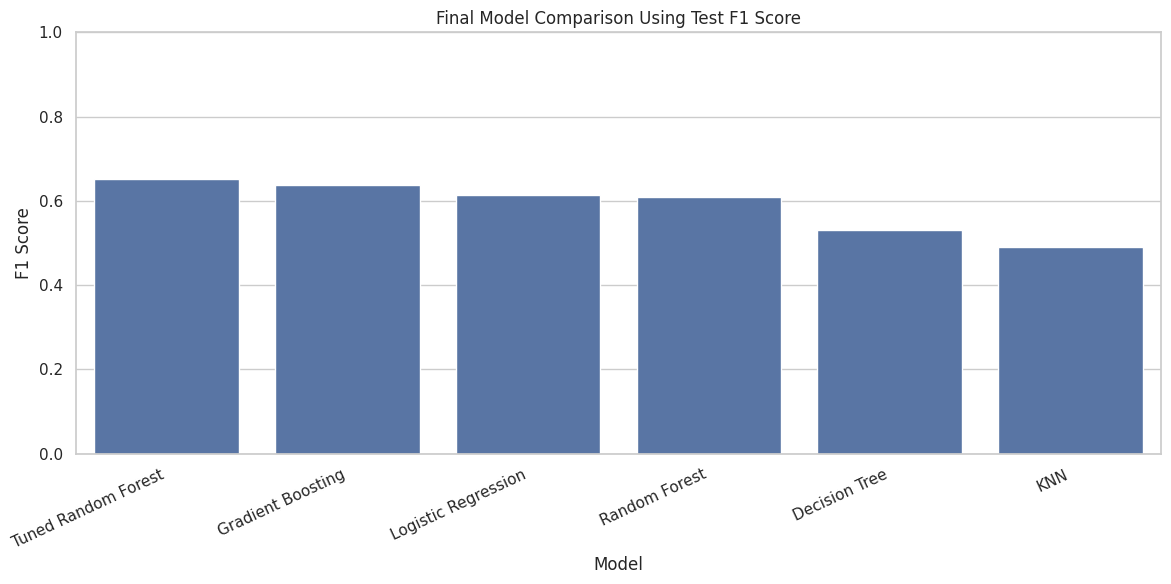

In [ ]:

all_models = {
    **baseline_pipelines,
    **advanced_pipelines,
    "Tuned Random Forest": tuned_rf
}

final_results = []
test_predictions = {}
test_probabilities = {}

for name, model in all_models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = predictions
    test_probabilities[name] = probabilities

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

final_table = pd.DataFrame(final_results)
final_table = final_table.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(final_table.round(4))

plt.figure(figsize=(12, 6))
sns.barplot(data=final_table, x="Model", y="F1 Score")
plt.title("Final Model Comparison Using Test F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

best_model_name = final_table.iloc[0]["Model"]
best_model = all_models[best_model_name]

y_pred = test_predictions[best_model_name]
y_prob = test_probabilities[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 4))
print("F1 Score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))


Selected model: Tuned Random Forest

Classification Report:

              precision    recall  f1-score   support

 No Purchase       0.94      0.93      0.93      3127
    Purchase       0.64      0.66      0.65       572

    accuracy                           0.89      3699
   macro avg       0.79      0.80      0.79      3699
weighted avg       0.89      0.89      0.89      3699

Accuracy: 0.8902
Precision: 0.6402
Recall: 0.6626
F1 Score: 0.6512
ROC-AUC: 0.9212


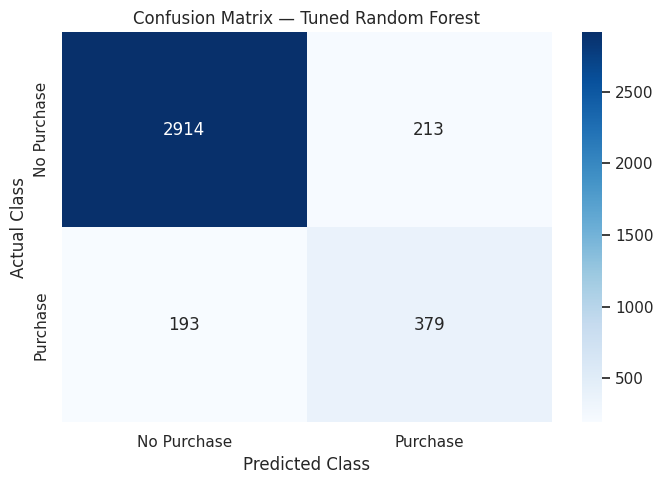

In [ ]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


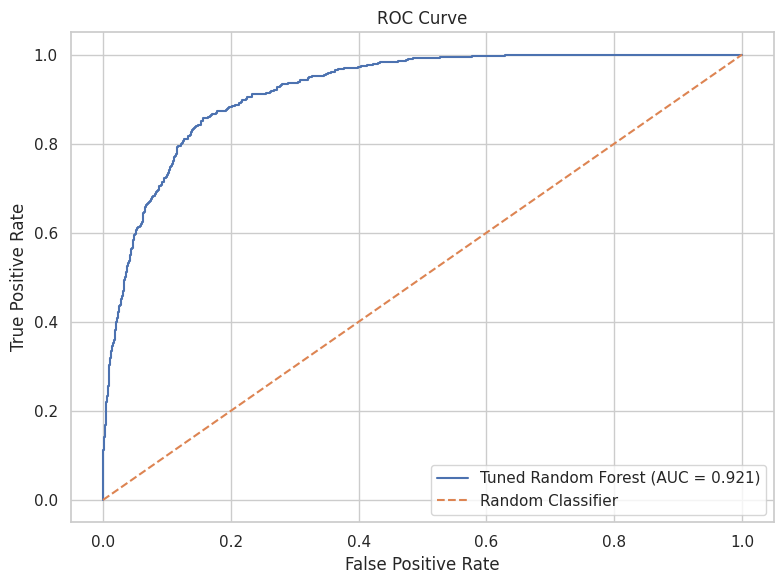

ROC-AUC Score: 0.9212


In [ ]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {auc_value:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(auc_value, 4))


Top 15 important features:


,Feature,Importance
8,num__PageValues,0.426031
7,num__ExitRates,0.095658
5,num__ProductRelated_Duration,0.082007
4,num__ProductRelated,0.063125
6,num__BounceRates,0.054900
1,num__Administrative_Duration,0.041530
0,num__Administrative,0.033559
21,cat__Month_Nov,0.028228
13,num__TrafficType,0.021842
12,num__Region,0.019531


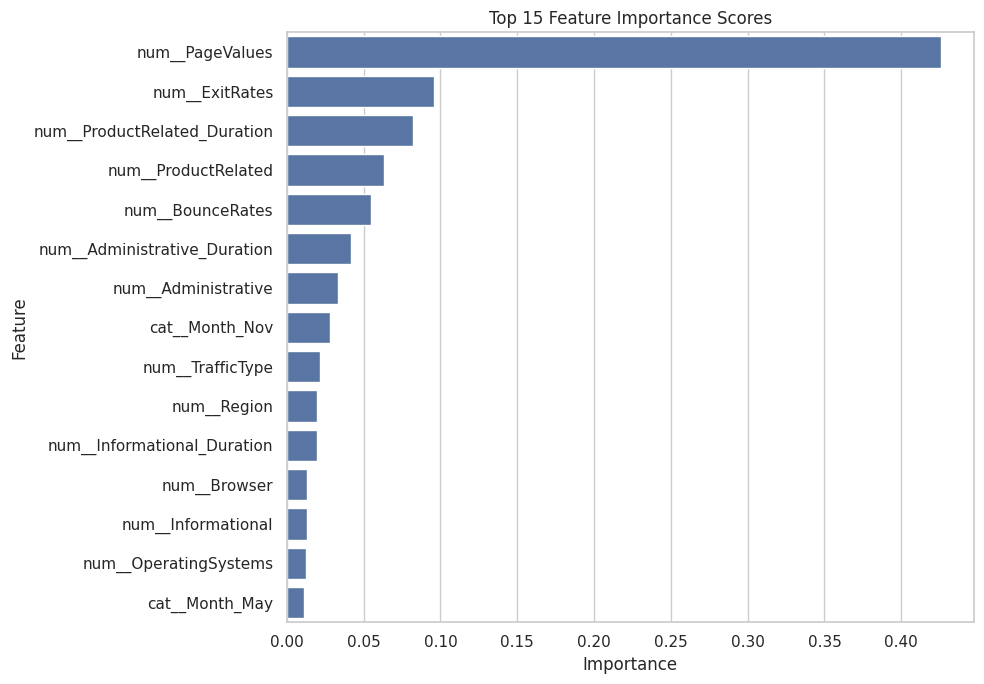

In [ ]:

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_classifier, "feature_importances_"):
    importance_values = fitted_classifier.feature_importances_

elif hasattr(fitted_classifier, "coef_"):
    importance_values = np.abs(
        fitted_classifier.coef_
    ).ravel()

else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    print("Top 15 important features:")
    display(importance_df.head(15))

    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )
    plt.title("Top 15 Feature Importance Scores")
    plt.tight_layout()
    plt.show()

else:
    print(
        "This model has no built-in feature importance or coefficients. "
        "Permutation importance can be used instead."
    )


In [ ]:

class_counts = y_train.value_counts().sort_index()

imbalance_table = pd.DataFrame({
    "Class": ["No Purchase", "Purchase"],
    "Count": [
        int(class_counts.get(0, 0)),
        int(class_counts.get(1, 0))
    ]
})

imbalance_table["Percentage"] = (
    imbalance_table["Count"] / len(y_train) * 100
).round(2)

display(imbalance_table)

print(
    "\nClass imbalance is addressed in selected models using class_weight. "
    "SMOTE is an alternative and should only be applied to training folds, "
    "never to the test set."
)


,Class,Count,Percentage
0,No Purchase,7295,84.52
1,Purchase,1336,15.48



Class imbalance is addressed in selected models using class_weight. SMOTE is an alternative and should only be applied to training folds, never to the test set.


In [ ]:

best_row = final_table.iloc[0]

print("=" * 60)
print("PROJECT CONCLUSION")
print("=" * 60)

print("\nProject: Online Shoppers' Purchase Intention Prediction")
print("Problem type: Supervised Learning — Classification")
print("Target variable: Revenue")

print("\nSelected model:", best_model_name)
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1 Score:", round(best_row["F1 Score"], 4))
print("ROC-AUC:", round(best_row["ROC-AUC"], 4))

print("\nBusiness insights:")
print(
    "The model can help an e-commerce business study browsing sessions "
    "associated with completed purchases. Feature importance can help "
    "identify patterns that are useful for further investigation."
)

print("\nLimitations:")
print(
    "Predictions depend on the available dataset and may not generalize "
    "to every website, customer group, or time period. The model identifies "
    "associations and does not establish causation."
)

print("\nFuture improvements:")
print(
    "Test on newer data, evaluate different decision thresholds, improve "
    "feature engineering, and validate performance on another dataset."
)


PROJECT CONCLUSION

Project: Online Shoppers' Purchase Intention Prediction
Problem type: Supervised Learning — Classification
Target variable: Revenue

Selected model: Tuned Random Forest
Accuracy: 0.8902
Precision: 0.6402
Recall: 0.6626
F1 Score: 0.6512
ROC-AUC: 0.9212

Business insights:
The model can help an e-commerce business study browsing sessions associated with completed purchases. Feature importance can help identify patterns that are useful for further investigation.

Limitations:
Predictions depend on the available dataset and may not generalize to every website, customer group, or time period. The model identifies associations and does not establish causation.

Future improvements:
Test on newer data, evaluate different decision thresholds, improve feature engineering, and validate performance on another dataset.


In [ ]:

# Save the trained model
joblib.dump(best_model, "online_shoppers_final_model.joblib")

# Save the comparison results
final_table.to_csv(
    "online_shoppers_model_comparison.csv",
    index=False
)

# Download files from Google Colab
from google.colab import files

files.download("online_shoppers_final_model.joblib")
files.download("online_shoppers_model_comparison.csv")

print("Final model and comparison table saved successfully.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final model and comparison table saved successfully.
